# 03 — The mortgage rate borrowers refinance against

Prepayment depends on the rate a borrower can get today, the Freddie Mac PMMS 30-year fixed rate, not on a
Treasury yield. The pricer therefore needs a map from simulated Treasury yields to that rate.

**Which benchmark?** A 30-year mortgage is not a 30-year bond. Its cash flows (average life roughly 6–9
years) sit in the 5–10Y sector, and the rate lenders quote follows the current-coupon MBS yield. Street
prepayment models therefore drive the mortgage rate off the 2Y and 10Y swap or Treasury rates. The 30Y
Treasury is not used, and the comparison below shows why.

**Model** (weekly, PMMS aligned to Mon–Wed survey-window yields, June 2022 onward, the post-QE regime):

$$\text{PMMS}_t = a + b_2\,\text{CMT2}_t + b_{10}\,\text{CMT10}_t + e_t,\qquad e_t=\rho\,e_{t-1}+u_t$$

**Estimation.** The series are persistent, so the long-run coefficients are estimated by dynamic OLS (±4 weeks
of leads and lags of the differenced regressors) with Newey–West errors, which keeps the intervals valid.
$\rho$ is the AR(1) of the static residual, and Engle–Granger tests for cointegration.

**Projection.** $m(t)=a+b_2\,\text{CMT2}(t)+b_{10}\,\text{CMT10}(t)+e_0\,\rho^{\text{weeks}}$, where $e_0$ is
today's residual. The rate therefore starts at the latest PMMS print and the spread decays at the
estimated speed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps

ps.apply()
pd.set_option("display.width", 140)
CUSIP = "3140QVLM4"

In [2]:
import statsmodels.api as sm
from mortgage_rate import DEFAULT_SAMPLE_START, fit_mortgage_rate_model, survey_panel
from run_security_analytics import load_inputs

inputs = load_inputs(CUSIP)
trade, cmt, pmms = inputs["trade_date"], inputs["cmt"], inputs["pmms"]
panel = survey_panel(pmms, cmt)
fit = fit_mortgage_rate_model(panel, trade)
m = fit["model"]
pd.DataFrame({
    "estimate": [m.const * 100, m.beta_2y, m.beta_10y, fit["sum_betas"], m.rho_weekly],
    "HAC se": [fit["coef_se"]["const"] * 100, fit["coef_se"]["cmt2"], fit["coef_se"]["cmt10"],
               fit["sum_betas_se"], fit["rho_se"]],
}, index=["a (%)", "b2 (2Y)", "b10 (10Y)", "b2 + b10 (parallel move)", "rho (weekly)"]).round(3)

,estimate,HAC se
a (%),2.630,0.231
b2 (2Y),0.571,0.043
b10 (10Y),0.385,0.063
b2 + b10 (parallel move),0.957,0.056
rho (weekly),0.853,0.035


In [3]:
print(f"sample {fit['sample_start']} to {fit['sample_end']} ({fit['n_weeks']} weeks); "
      f"residual sd {fit['residual_sd'] * 1e4:.1f} bp; spread half-life {fit['half_life_weeks']:.1f} weeks")
print(f"Engle-Granger cointegration test p = {fit['engle_granger_pvalue']:.3f}")
print(f"latest PMMS {m.anchor_pmms * 100:.2f}% (released {fit['anchor_release']}); "
      f"today's residual e0 = {m.anchor_residual * 1e4:+.1f} bp")

sample 2022-06-02 to 2026-10-08 (228 weeks); residual sd 17.0 bp; spread half-life 4.4 weeks
Engle-Granger cointegration test p = 0.070
latest PMMS 7.40% (released 2026-10-08); today's residual e0 = -1.0 bp


### 2Y + 10Y against a 10Y-only or 30Y-only benchmark

Same sample. Levels R² and residual persistence measure how well each benchmark tracks the mortgage rate.
The weekly-change slope measures short-run pass-through.

In [4]:
tenors = [2.0, 5.0, 10.0, 30.0]
rows = []
for release, rate in pmms.items():
    win = cmt.loc[release - pd.Timedelta(days=3): release - pd.Timedelta(days=1), tenors]
    if len(win):
        rows.append({"release": release, "pmms": rate, **{f"y{int(k)}": v for k, v in win.mean().items()}})
weekly = pd.DataFrame(rows).set_index("release").loc[DEFAULT_SAMPLE_START:trade]

def compare(columns):
    lev = sm.OLS(weekly["pmms"], sm.add_constant(weekly[columns])).fit()
    e = lev.resid
    rho = np.corrcoef(e[1:], e[:-1])[0, 1]
    chg = sm.OLS(weekly["pmms"].diff().dropna(), sm.add_constant(weekly[columns].diff().dropna())).fit()
    return {"levels R2": lev.rsquared, "resid sd (bp)": e.std() * 1e4,
            "half-life (weeks)": np.log(0.5) / np.log(rho),
            "weekly-change R2": chg.rsquared,
            "change pass-through (sum)": chg.params[columns].sum()}

pd.DataFrame({name: compare(cols) for name, cols in
              {"30Y only": ["y30"], "10Y only": ["y10"], "5Y only": ["y5"], "2Y + 10Y": ["y2", "y10"]}.items()}).T.round(3)

,levels R2,resid sd (bp),half-life (weeks),weekly-change R2,change pass-through (sum)
30Y only,0.279,39.326,22.879,0.478,0.786
10Y only,0.566,30.518,20.230,0.582,0.776
5Y only,0.806,20.379,6.413,0.555,0.687
2Y + 10Y,0.869,16.772,4.254,0.582,0.779


In [5]:
robust = {}
for start in ["2015-01-01", "2020-01-01", "2022-06-01", "2023-01-01"]:
    f = fit_mortgage_rate_model(panel, trade, start=start)
    robust[start] = {"b2": f["model"].beta_2y, "b10": f["model"].beta_10y, "b2+b10": f["sum_betas"],
                     "half-life (w)": f["half_life_weeks"], "resid sd (bp)": f["residual_sd"] * 1e4,
                     "EG p-value": f["engle_granger_pvalue"]}
pd.DataFrame(robust).T.round(3)

,b2,b10,b2+b10,half-life (w),resid sd (bp),EG p-value
2015-01-01,0.508,0.548,1.056,18.958,26.830,0.277
2020-01-01,0.692,0.302,0.994,6.787,20.599,0.114
2022-06-01,0.571,0.385,0.957,4.362,16.981,0.070
2023-01-01,0.577,0.358,0.935,4.884,16.660,0.329


The loadings shift between windows, but their sum, which is what a parallel curve move passes through,
stays between 0.94 and 1.06. Over 2022–26 the 2Y carries much of the level relation: the mortgage spread to
the 10Y was widest while the curve was inverted. Week to week, the 10Y does almost all the work.

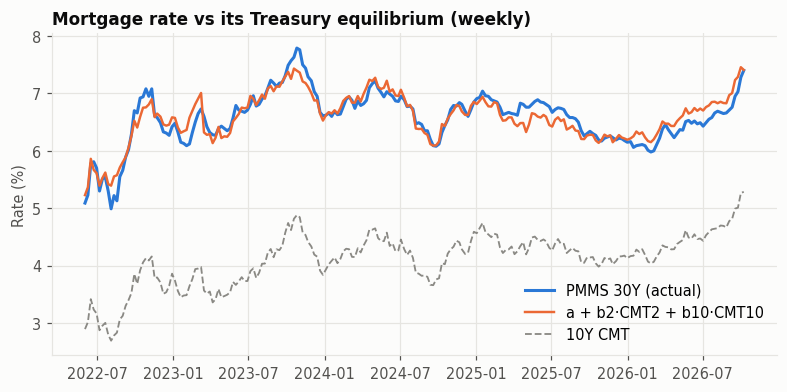

In [6]:
sample = panel.loc[DEFAULT_SAMPLE_START:trade]
fitted = m.equilibrium(sample["cmt2"], sample["cmt10"])
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(sample.index, sample["pmms"] * 100, color=ps.SERIES[0], label="PMMS 30Y (actual)")
ax.plot(sample.index, fitted * 100, color=ps.SERIES[1], linewidth=1.6, label="a + b2·CMT2 + b10·CMT10")
ax.plot(sample.index, sample["cmt10"] * 100, color=ps.REFERENCE, linewidth=1.2, linestyle="--", label="10Y CMT")
ax.set(ylabel="Rate (%)", title="Mortgage rate vs its Treasury equilibrium (weekly)")
ax.legend(loc="lower right")
_ = ps.save(fig, "03_mortgage_rate_fit")